# ANA-065 — RUN-168 replicate-aware empirical statistics and frozen observation models

**EXP-065 · RUN-168 · TrpB · descriptive analysis, 7 October 2026**

Replicate disagreement alone does not explain the previous high-order WHT discrepancy. Cross-replicate estimates remain close to the original mean per-cube fraction. Shared assay variation is consequential, but the stop-control correction is too assumption-dependent and unstable near the floor to identify an error-free biological target. Adding observation noise to the frozen models moves high-order fractions and diminishing-returns slopes toward the measured means while increasing an already larger fitness spread. This is partial, conditional agreement across summaries.

A second finding changes how the discrepancy should be described: **the mean of per-cube fractions is 0.2668, whereas the ratio of pooled high-order to total power is 0.1025**. These answer different questions. Three of the 24 confirmation cubes contain 74.7% of ordinary total power. Neither weighting replaces the other, and the pooled statistic cannot retrospectively establish overall model adequacy.


This is the canonical executable analysis. Run all cells to audit inputs and reproduce every table and figure.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
import matplotlib.pyplot as plt
here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / 'labproject.yaml').is_file())
analysis = root / 'analyses/2026-10-07_ANA-065_run-168-replicate-aware-statistics-and-observation-models'
sys.path.insert(0, str(analysis / 'notebooks'))
import analysis_tools as tools


## Verify the record before interpreting it

The following audit independently verifies checksums, original data, split isolation, frozen parameters, observation draws, WHT, and mutation-slope components. Assertions check numerical consistency, not scientific acceptance.

In [2]:
context = tools.audit_and_load()
print({key: context['audit'][key] for key in ['remote_hashes', 'empirical_measurements', 'synthetic_pair_cubes', 'synthetic_statistic_rows', 'replayed_observation_values']})

Audit complete: 131,584 replicate-pair cubes, 394,752 synthetic statistic rows; all checks agree.
{'remote_hashes': 162, 'empirical_measurements': 768, 'synthetic_pair_cubes': 131584, 'synthetic_statistic_rows': 394752, 'replayed_observation_values': 4210688}


## Design and estimators

This is a diagnostic reanalysis of exposed RUN-166 data, not fresh empirical confirmation. We retain all 48 empirical cubes, including the original 24 confirmation cubes; eight frozen linear/sigmoid × interaction-ratio arms with 64 confirmation cubes each; and the original calibration offset −0.061047396 and range 0.66408129. The generator, affine parameters, and selected sigmoid settings are unchanged. Each synthetic arm receives 128 observation draws under each of two measurement assumptions. Those draws reuse eight landscape seeds and are not independent landscapes.

Original measurements and processing code come from [Johnston et al. (2024)](https://doi.org/10.1073/pnas.2400439121) and its [CaltechDATA deposit](https://data.caltech.edu/records/h5rah-5z170). Both replicate fitness estimates use averaged input counts; stop subtraction and maximum normalization are applied within timepoint/replicate before averaging selected timepoints. The analysis preserves those published scales and negative observations. Shared inputs and normalization mean that cross-replicate variation cannot be interpreted as exclusively biological.

For each four-site binary cube, the Walsh coefficient is its signed contrast divided by 16. Ordinary power is the squared coefficient of the replicate average; cross-power is the product of corresponding replicate coefficients. The stop-adjusted sensitivity subtracts `choose(4,k) × sum(q_i) / 256` at order k, where each q_i is the training-stop cross covariance in that vertex's input-depth quartile. High-order means orders **3–4**, while epistatic means orders **2–4**. Signed powers are retained. Fractions require a positive resolved total; they may exceed one or be negative after correction.

A fixed 0→1 mutation is evaluated on its eight backgrounds. The cross slope uses the mean of the two cross-replicate effect/background covariances divided by background cross covariance. The stop sensitivity adds `(7/8) × mean(q_low)` to the numerator and subtracts it from the denominator. These corrections assume independent errors between distinct genotypes. Every numerator, denominator, signed mean effect and eligibility mask is retained; undefined ratios are never replaced with zero. All eligible mutations are primary; the beneficial subset additionally requires mean effect above resolution and is itself selected using noisy measurements.

The primary resolution is 0.001 in RUN-166 coordinates, with 10⁻¹² and 0.01 sensitivities. These are descriptive resolutions, not noise estimates. Empirical intervals use 2,000 paired cube resamples with noise calibration fixed. They omit uncertainty in the control model and dependence through shared sites/alleles. Synthetic shaded ranges are the central 95% of the 128 observation realizations on fixed landscapes, **not** confidence intervals for model generalization. No scientific acceptance thresholds or new joint discrepancy fit are introduced.



In [3]:
context = tools.summarize(context)
display(context['esummary'].query("split == 'confirmation' and resolution == 0.001 and stratum == 'all'")[[
    'method', 'mean_cube_ho_fraction', 'aggregate_ho_fraction', 'power_available_n',
    'mean_slope', 'slope_mutations_n', 'mean_beneficial_slope', 'beneficial_mutations_n'
]])

,method,mean_cube_ho_fraction,aggregate_ho_fraction,power_available_n,mean_slope,slope_mutations_n,mean_beneficial_slope,beneficial_mutations_n
36,average,0.266817,0.102539,24,-0.922821,96,-1.029183,47
37,cross,0.267116,0.097190,24,-1.224911,96,-1.882297,47
38,stop_adjusted,0.678053,0.063224,12,-0.617031,43,-0.957824,16


## 1. Most sampled vertices lie below the activity criterion

Only **32/384 confirmation vertices (8.3%)** exceed both published replicate activity cutoffs, approximately 0.054. Twelve cubes contain no active vertices, twelve contain some, and none contain sixteen. This is the original complete-cube panel, retained without activity selection. “No active vertices” means below the assay's detection criterion; it does not prove identical or absent biological fitness.

Noise estimation excludes 1,664 previously exposed genotypes. The remaining non-stop pool contains **125,972 training and 31,493 held-out donors**; controls contain **27,232 training and 6,809 held-out stop variants**. All 16 fitness/depth donor cells have sufficient observations for direct estimates, so no fallback is used. Held-out/training differential-variance ratios span **0.784–1.060**. Stop cross covariance declines with depth, from **9.37×10⁻⁴ to 2.01×10⁻⁴** in the training set and **9.94×10⁻⁴ to 2.00×10⁻⁴** in held-out controls, in raw fitness-squared units.

The control holdout supports the repeatability of these control summaries. It does not establish that their covariance is pure measurement error or transfers unchanged to functional variants. Stop biology, shared input sampling and normalization remain confounded. Conditioning donor errors on measured mean fitness also uses a noisy proxy for latent fitness.

**Figure 1.** A: every confirmation measurement, with activity guides and the identity line. B–C: independent training/holdout partitions of controls by fixed training-depth quartile. D: each point is one predeclared non-stop fitness/depth cell; the diagonal is equality. No error parameter was tuned to reduce model–empirical disagreement.

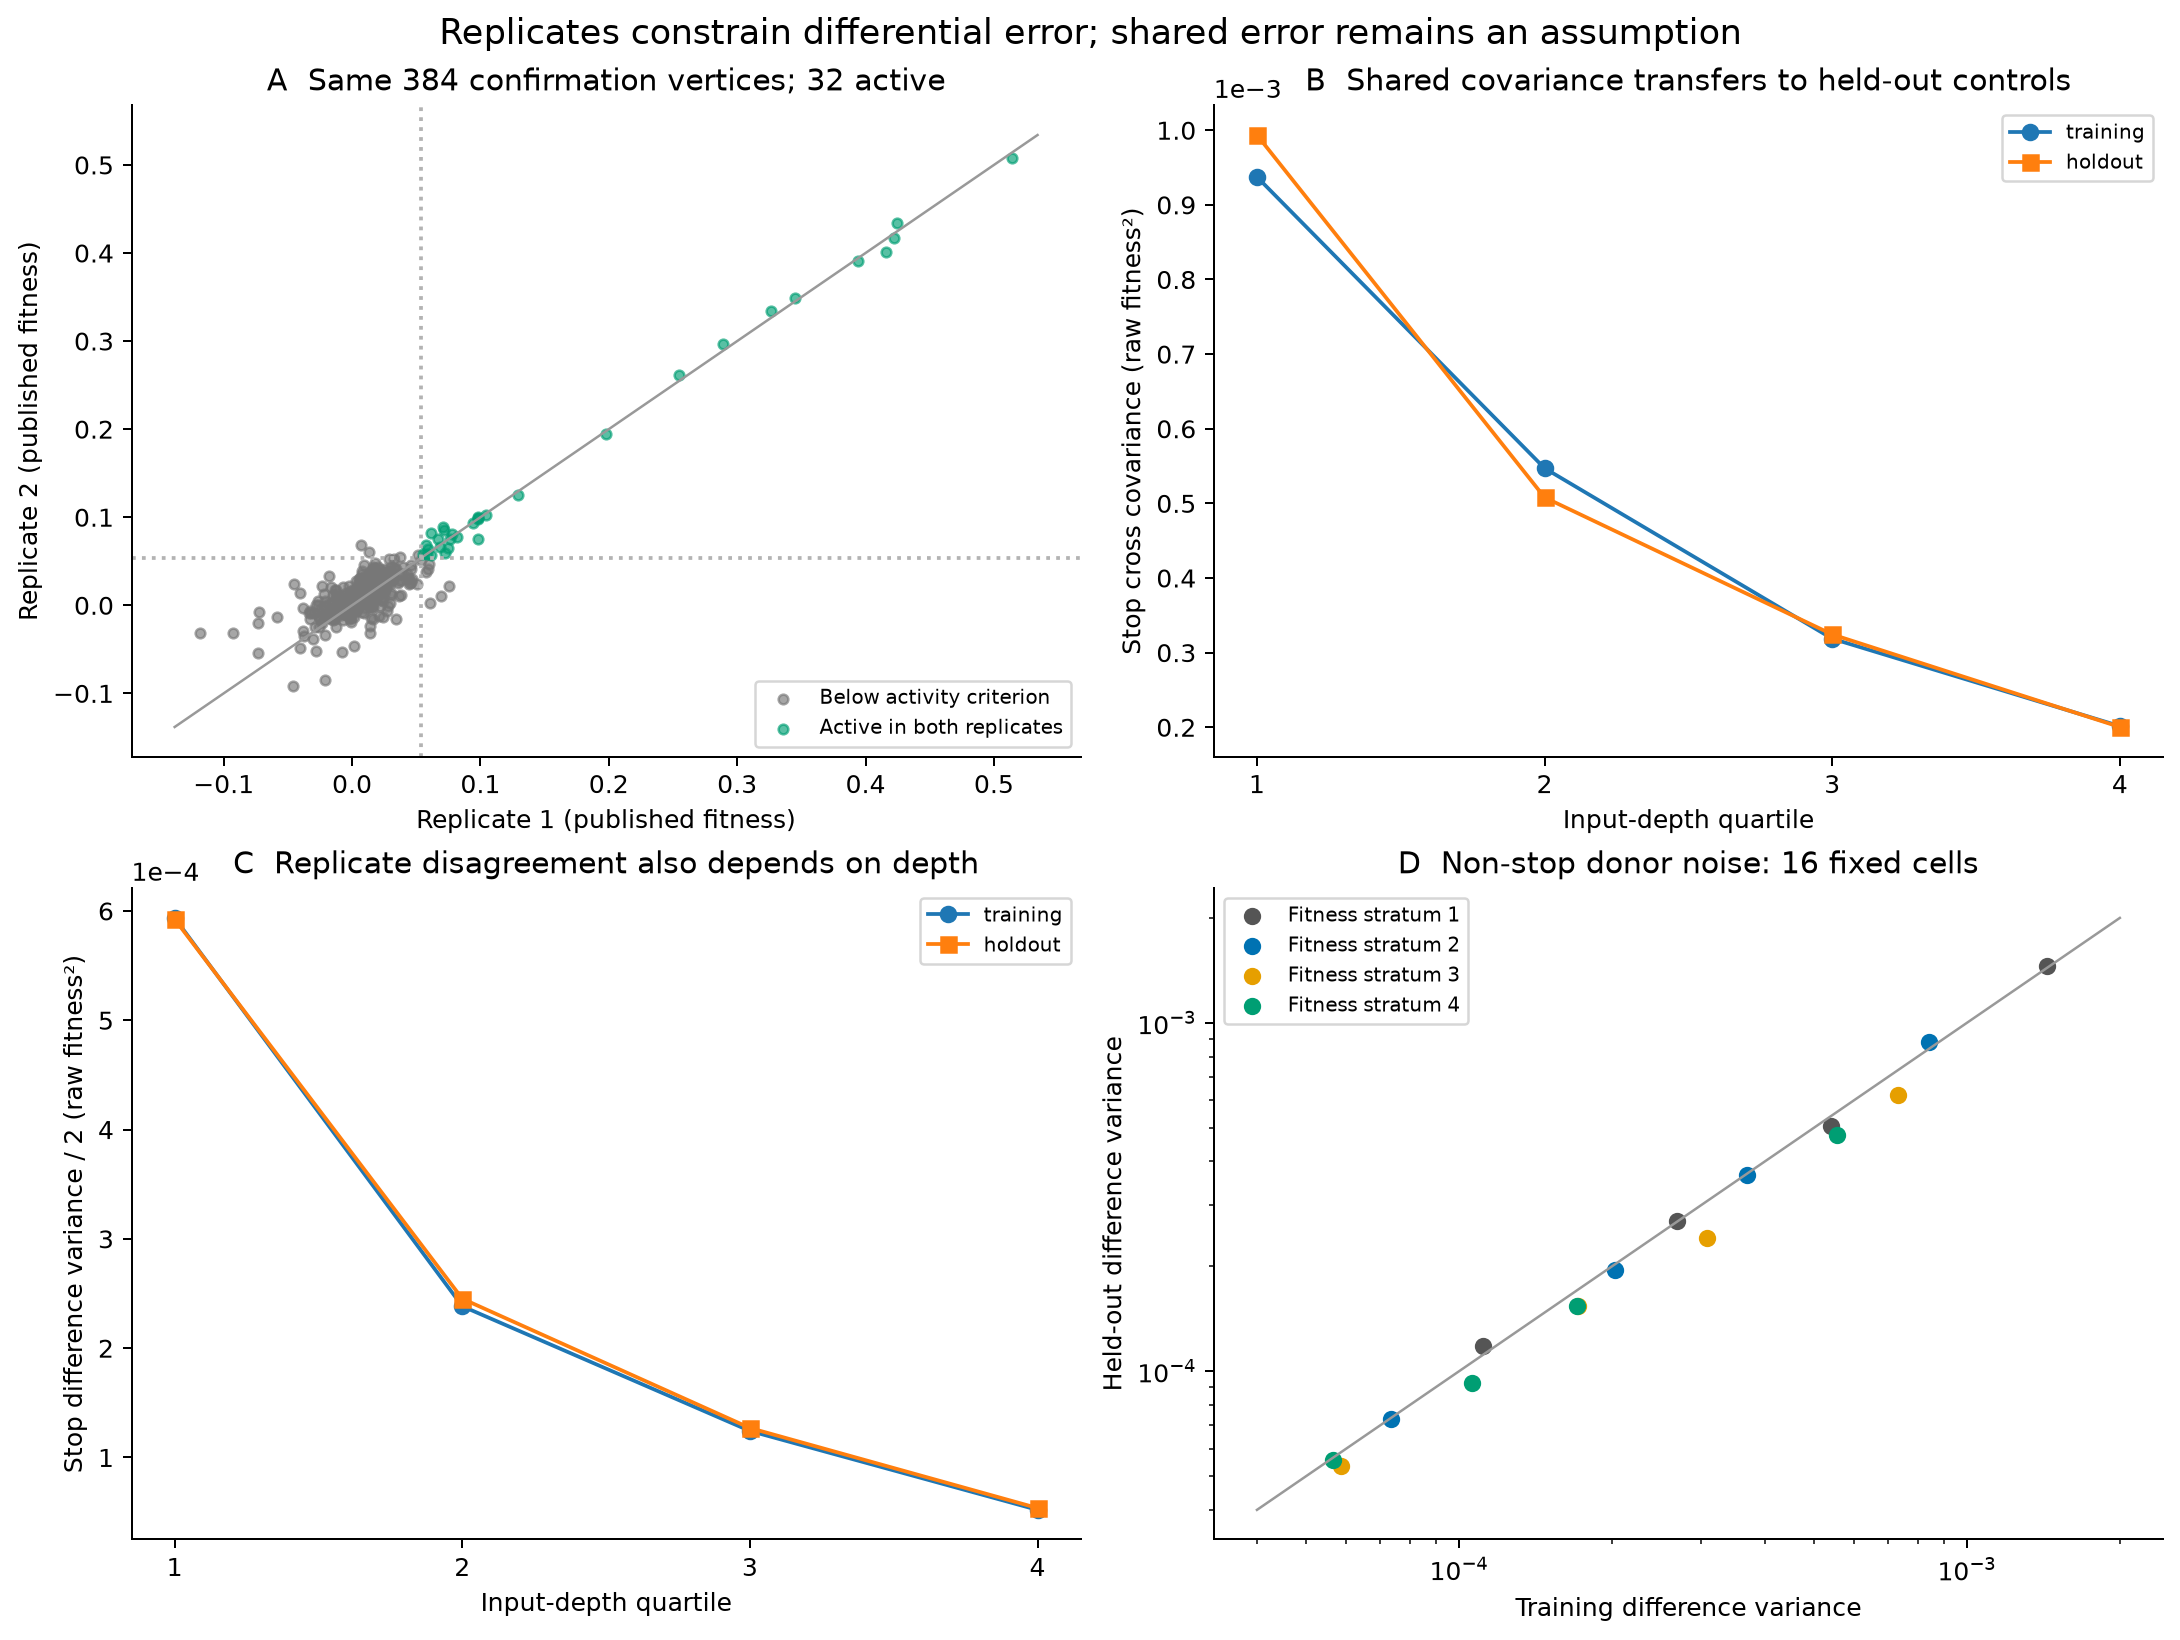

In [4]:
figure = tools.figure_measurement(context)
display(Image(filename=str(tools.FIGURES / '01_measurement_and_controls.png')))
plt.close(figure)

## 2. WHT depends on both measurement assumptions and weighting

The ordinary mean per-cube high-order fraction is **0.2668 [0.1955, 0.3447]**; the cross-replicate value is **0.2671 [0.1784, 0.3656]**. All 24 cubes remain resolved. Thus the observed discrepancy in this particular equal-cube summary survives removing the independent-error contribution in expectation. Correlated error is still present in the cross estimator.

Pooling signed powers before taking their ratio yields **0.1025 [0.0507, 0.2256]** ordinary and **0.0972 [0.0470, 0.2197]** cross-replicate. Pooling emphasizes cubes with more absolute variation; the equal-cube mean emphasizes the typical sampled resolved cube. Their divergence is a substantive feature of this panel, not a numerical inconsistency.

The stop sensitivity gives pooled fraction **0.0632 [0.0136, 0.1315]**, with **1,993/2,000** bootstrap ratios defined. However, **all 12 no-active cubes have negative adjusted total power**. They still contribute signed powers to the pooled calculation but cannot yield individual fractions. Among the 12 remaining resolved cubes, four signed fractions lie outside [0,1], including values approximately −0.564, −0.017, 2.661 and 4.473. Their mean is 0.6781 with a very wide interval [0.0309, 1.5699]. That increase is not evidence for stronger biological epistasis: it is a ratio instability and a changed resolved subset under an assumed correction.

**Figure 2.** A: mean order-specific absolute power with conditional cube-bootstrap intervals. B: equal-weight mean of defined per-cube fractions, with its availability count. C: ratio of summed powers, retaining all 24 signed estimates, even where a per-cube ratio is undefined. D: the same cubes before and after the stop-control adjustment. Symmetric-log axes retain negative estimates. Intervals omit uncertainty in q_i.

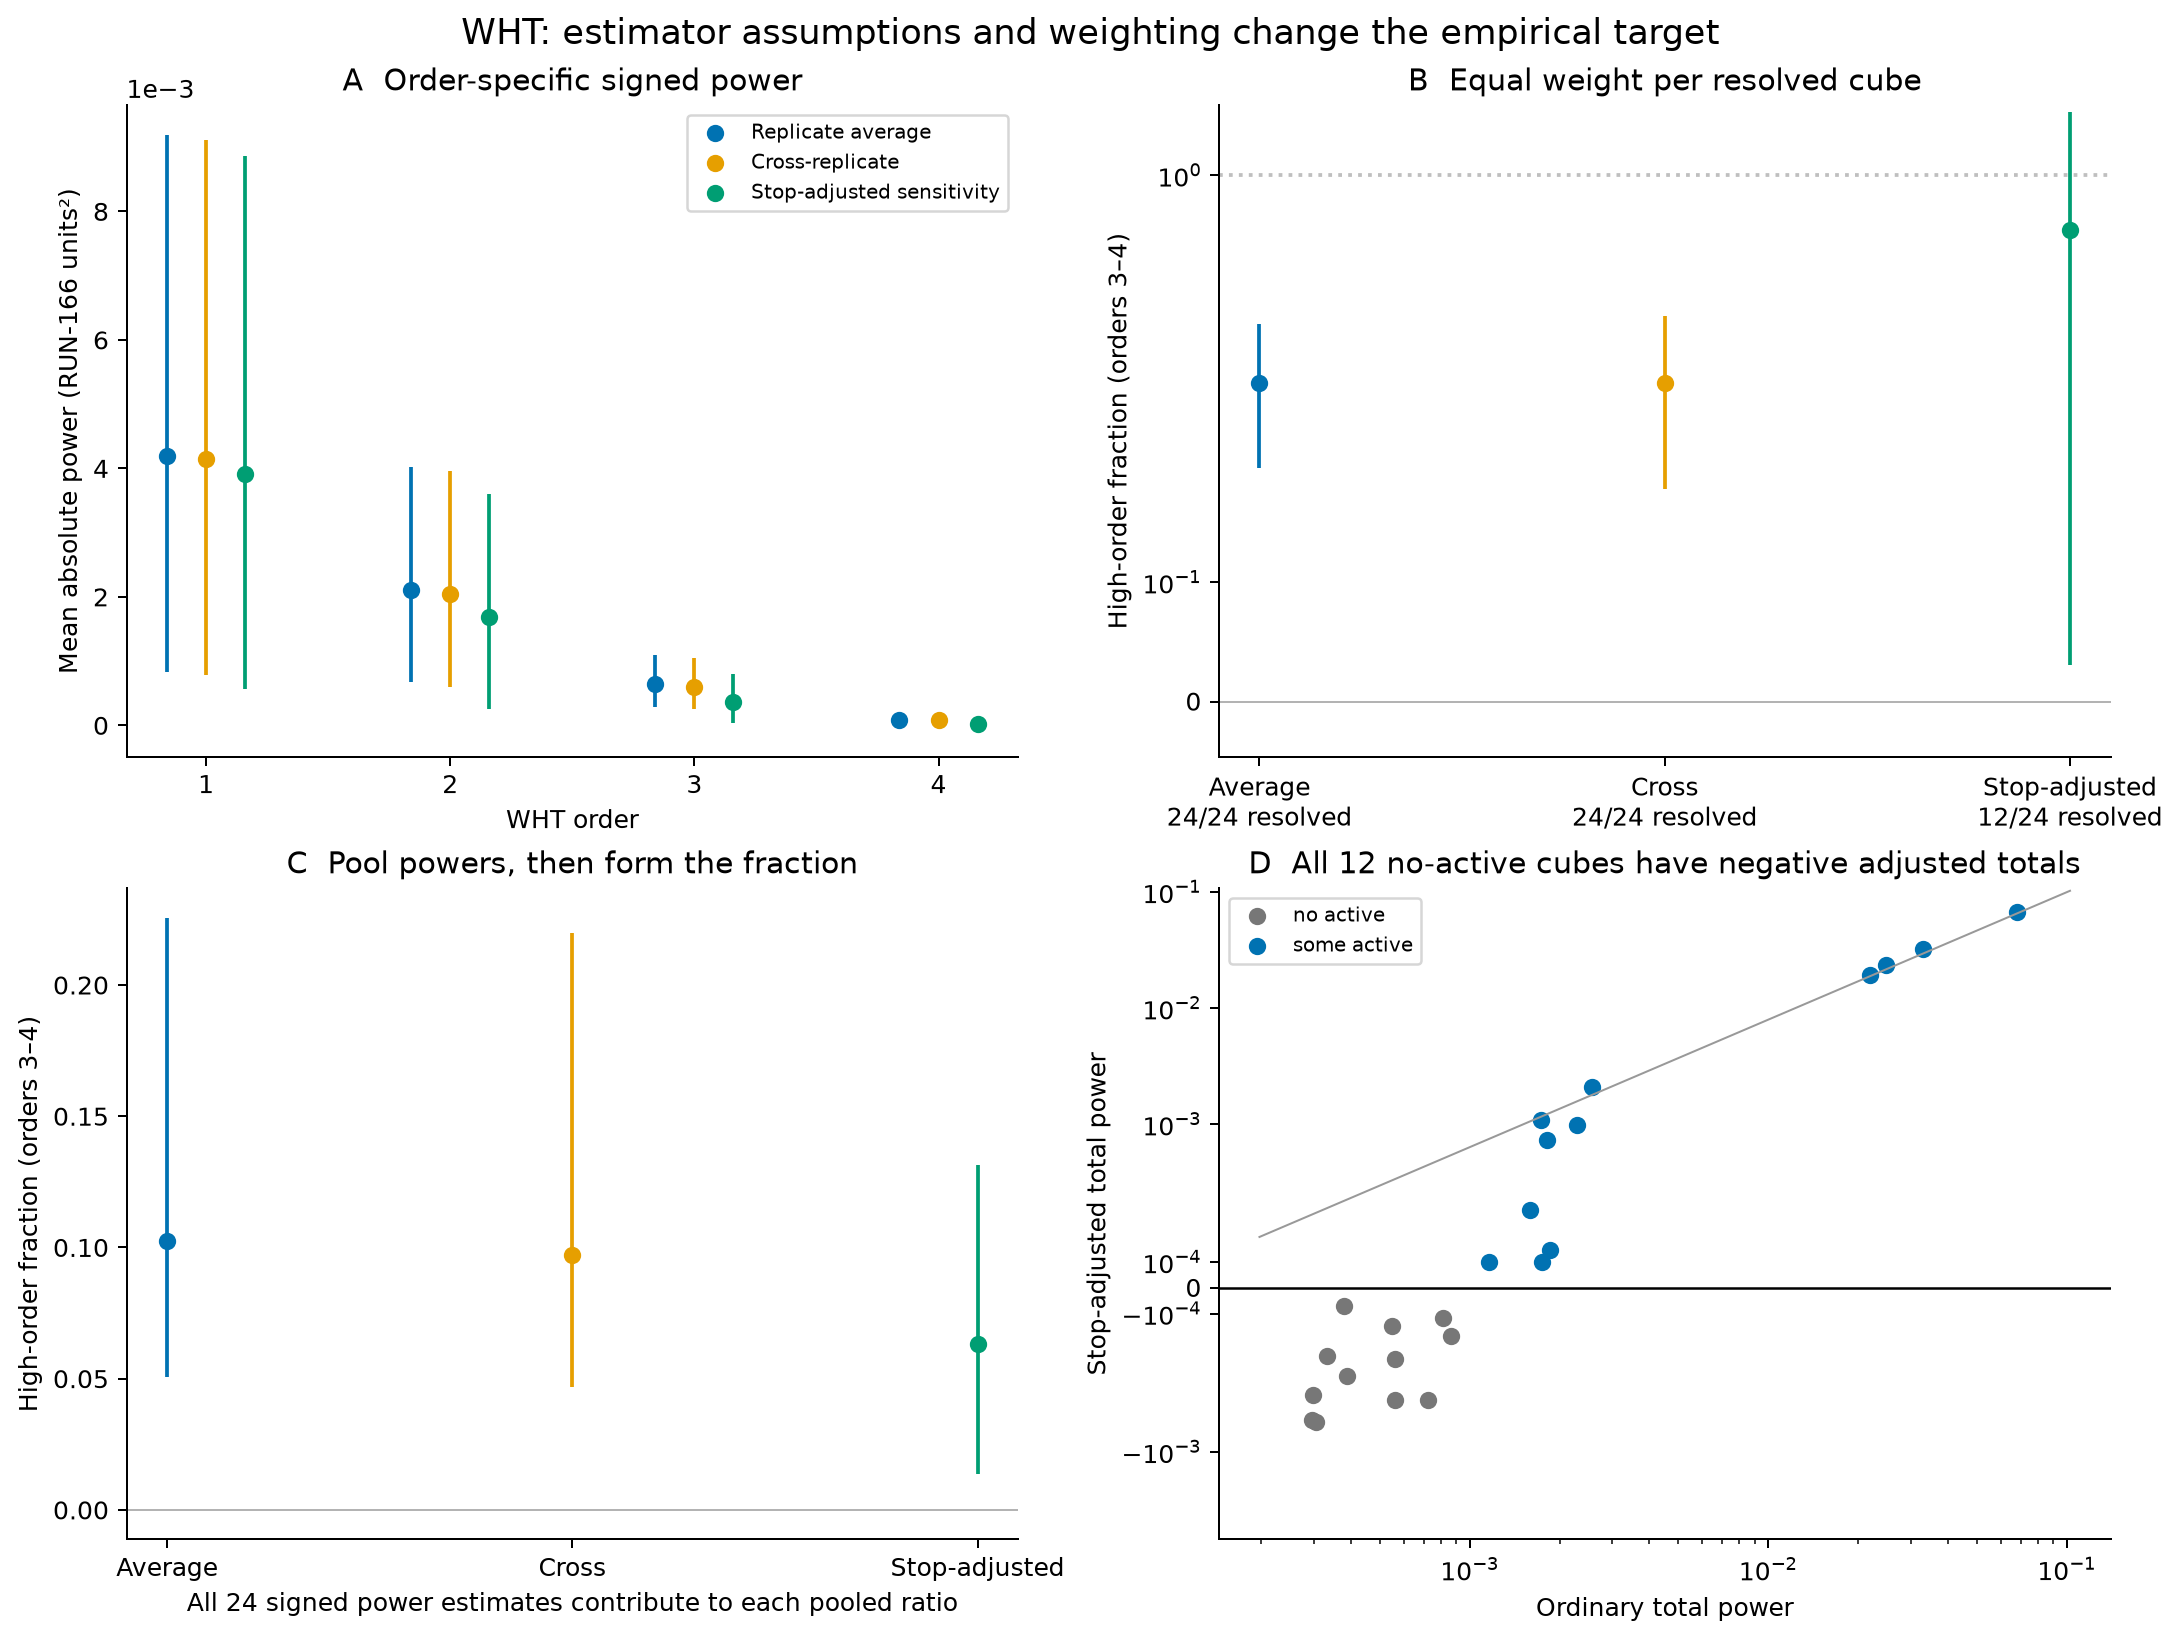

In [5]:
figure = tools.figure_wht(context)
display(Image(filename=str(tools.FIGURES / '02_wht_weighting_and_resolution.png')))
plt.close(figure)

## 3. A unique biological diminishing-returns rate is not identified

Across all eligible mutations, mean within-cube slope is **−0.923** ordinary, **−1.225** cross-replicate and **−0.617** stop-adjusted. The beneficial-subset means are **−1.029 [−1.262, −0.779]**, **−1.882 [−3.100, −0.925]**, and **−0.958 [−2.415, +0.538]**, respectively. Cross correction does not simply move slopes toward zero; ratios also change as the background covariance changes.

At primary resolution, the ordinary and cross estimators resolve **96/96 fixed mutations**, including **47 beneficial mutations**. Stop adjustment resolves **43/96**, including **16 beneficial mutations**. These are different available populations; comparing their means as if every estimator described the same resolved set would be misleading. The beneficial classification is noisy, and denominator instability can dominate individual slopes. The stored numerator/denominator tables and resolution sensitivity make that limitation inspectable.

**Figure 3.** A–B: conditional cube-bootstrap estimates for all mutations and the beneficial subset. C: resolved counts across all three declared resolutions. D: every stop-adjusted fixed-mutation numerator and denominator, including unresolved cases. A negative denominator is an estimator outcome under the assumed error model, not negative biological variance.

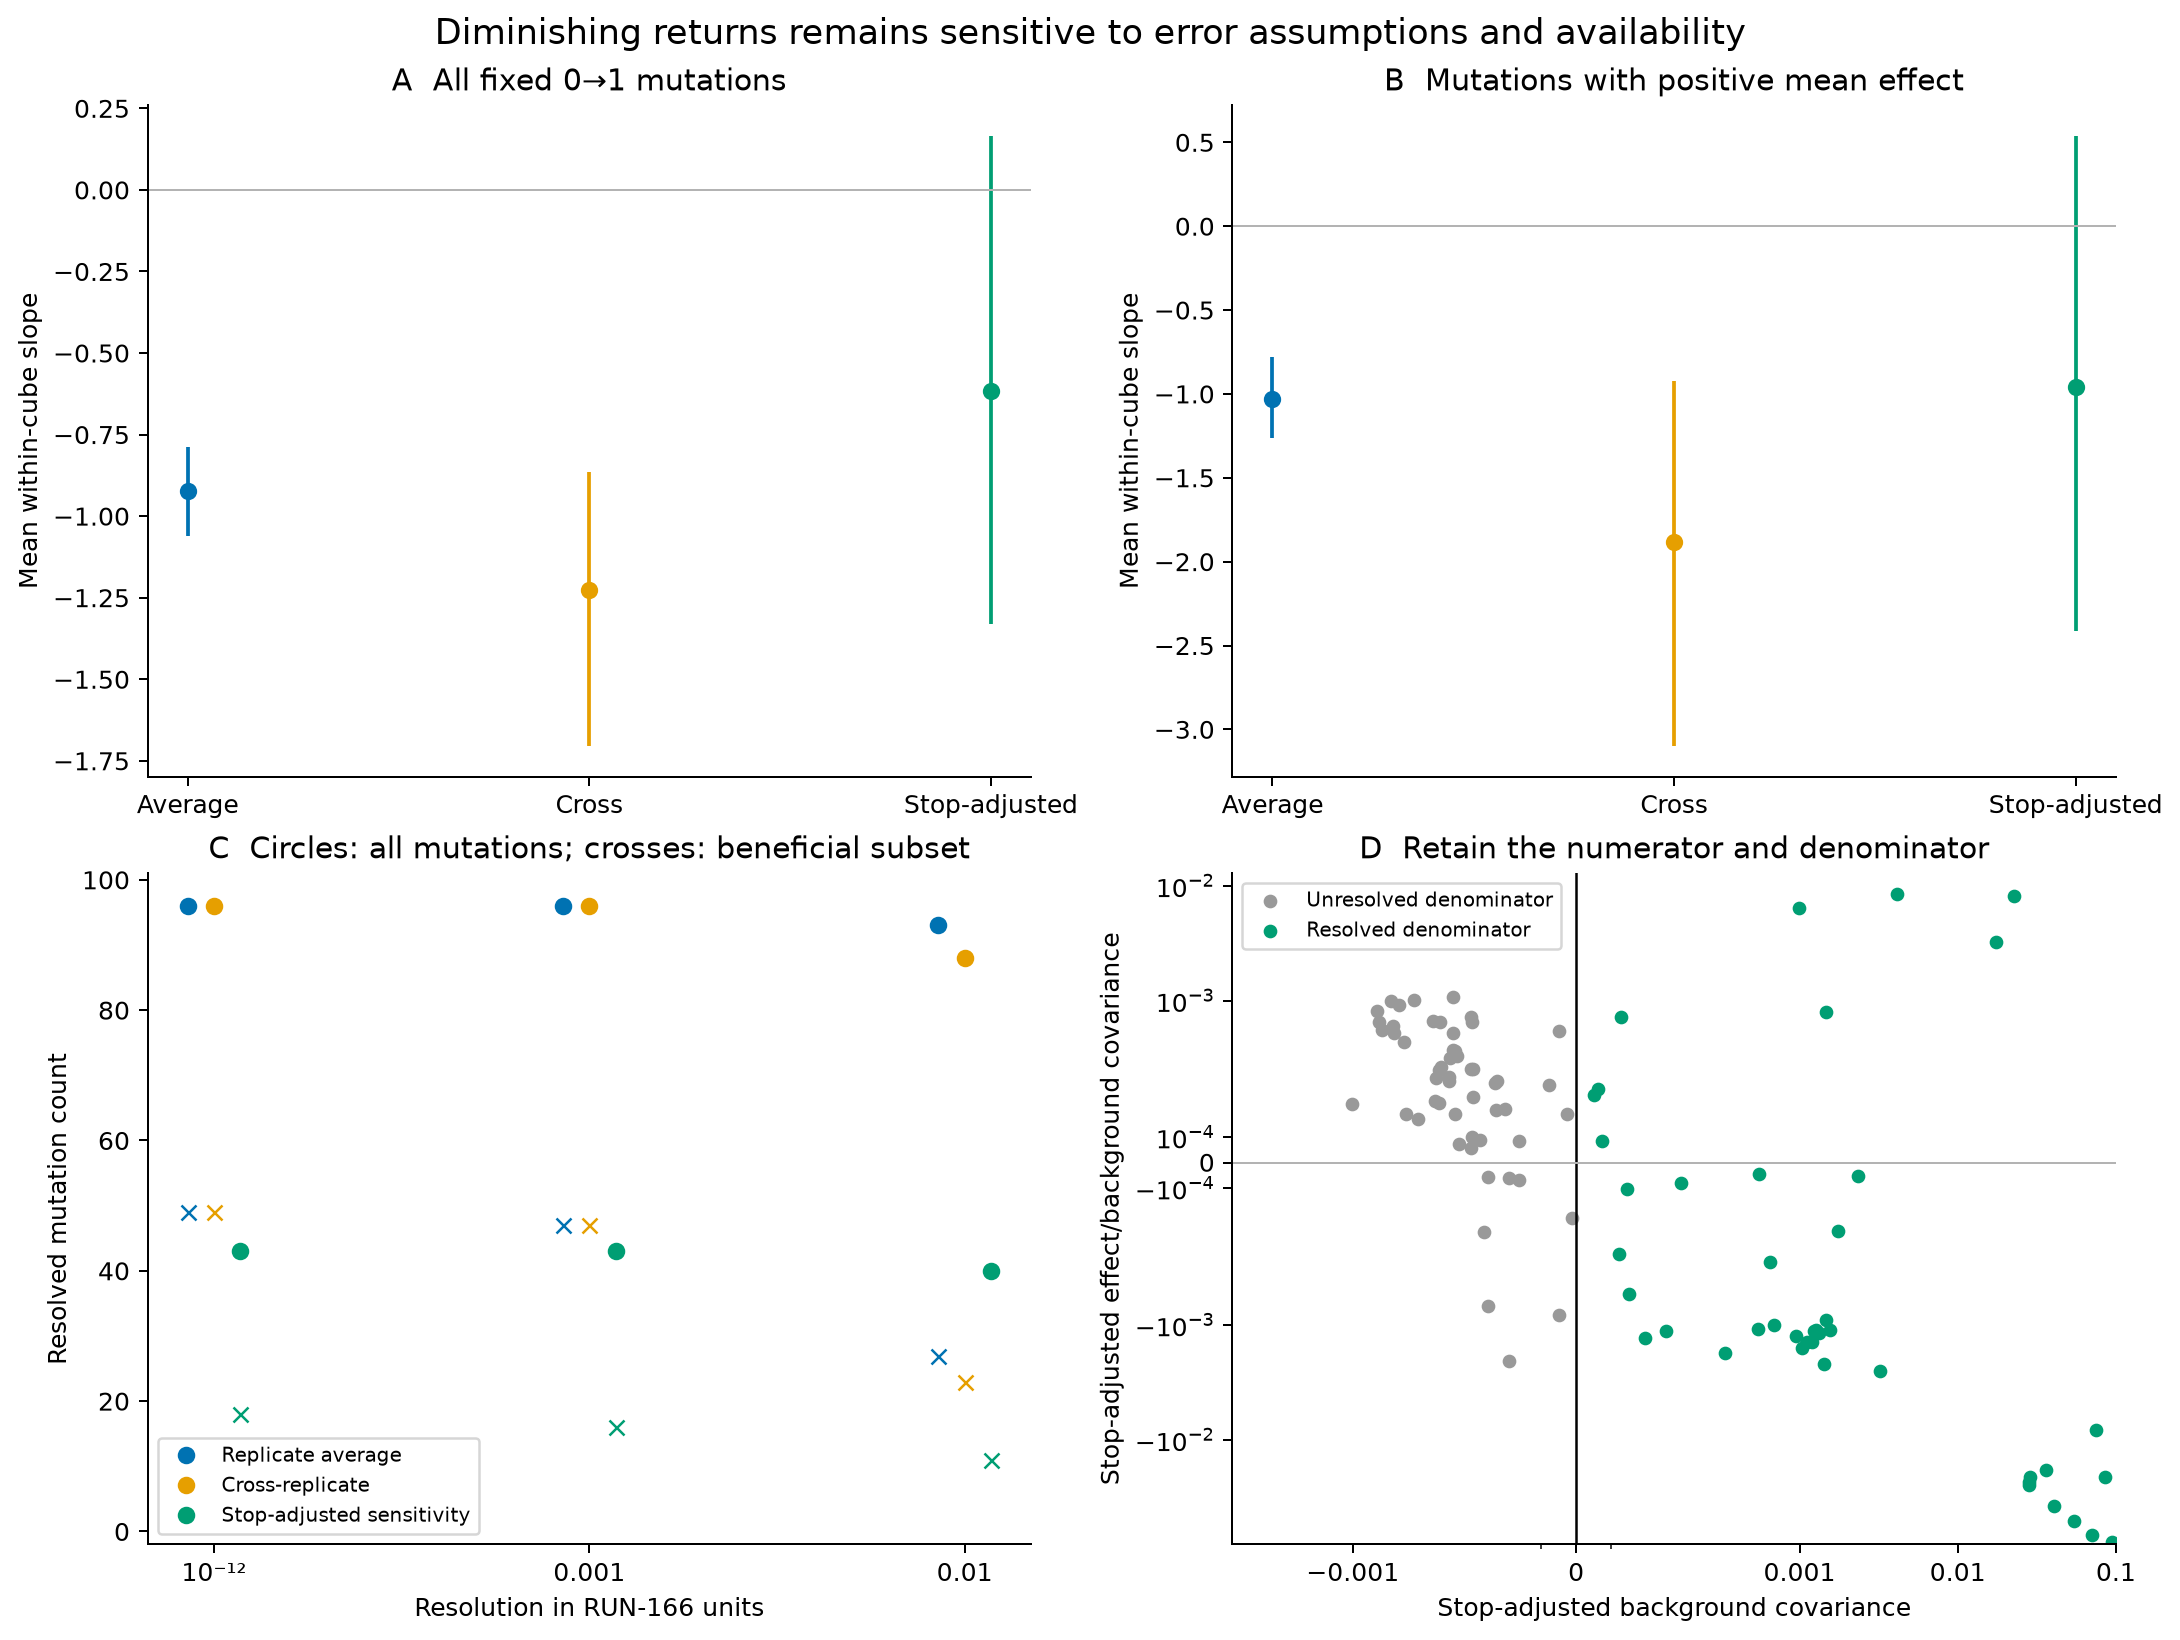

In [6]:
figure = tools.figure_slopes(context)
display(Image(filename=str(tools.FIGURES / '03_slopes_and_availability.png')))
plt.close(figure)

## 4. Observation noise explains part of the model–data difference

The independent-error arm resamples centered replicate differences within training fitness/depth cells, independently for each replicate with random sign reflection and division by √2. The shared-stop arm adds the same centered control-derived component to both replicas, with variance equal to the positive training-stop covariance in the assigned depth bin. Both arms use common random uniforms across frozen readouts and interaction ratios. Values are not clipped.

At the already selected **r=4**, the point estimates are:

| Model / observation | Mean cube WHT fraction ≥3 | Mean beneficial slope | Mean cube SD |
|---|---:|---:|---:|
| Measured replicate average | 0.2668 | −1.029 | 0.05644 |
| Linear, intrinsic | 0.1127 | −0.577 | 0.06537 |
| Linear, independent error | 0.1207 | −0.590 | 0.06661 |
| Linear, shared-stop sensitivity | 0.1554 | −0.656 | 0.07253 |
| Sigmoid, intrinsic | 0.1442 | −0.500 | 0.05990 |
| Sigmoid, independent error | 0.1540 | −0.580 | 0.06151 |
| Sigmoid, shared-stop sensitivity | 0.1885 | −0.692 | 0.06867 |

For the sigmoid shared-stop branch, the conditional observation ranges are **[0.1663, 0.2109]** for mean high-order fraction, **[−0.7835, −0.6085]** for beneficial slope and **[0.06623, 0.07049]** for SD. Shared variation has a larger effect than independent disagreement, but it also increases the spread discrepancy. The direction of change is not uniformly favourable across statistics.

The pooled-power comparison gives a further caution: intrinsic linear/sigmoid ratios **0.0927/0.1093** already lie close to the empirical **0.1025** point estimate, whereas shared-stop observation raises them to **0.1376/0.1540**. The apparent direction of improvement depends on whether the scientific target is a typical-cube fraction or the power-weighted aggregate. The complete table includes ordinary, cross and stop-adjusted comparisons at every resolution; none was selected to claim success.

**Figure 4.** Each row holds a readout fixed; colours change only the observation process. Curves cover all four frozen ratios. The empirical line is the ordinary replicate-average statistic. Grey bands are empirical conditional bootstrap intervals for the WHT and slope panels; coloured ranges are conditional observation variation, which excludes uncertainty in generator seeds and noise parameters. SD panels show the empirical point reference without a bootstrap band. The intrinsic reference is deterministic for these saved cubes.

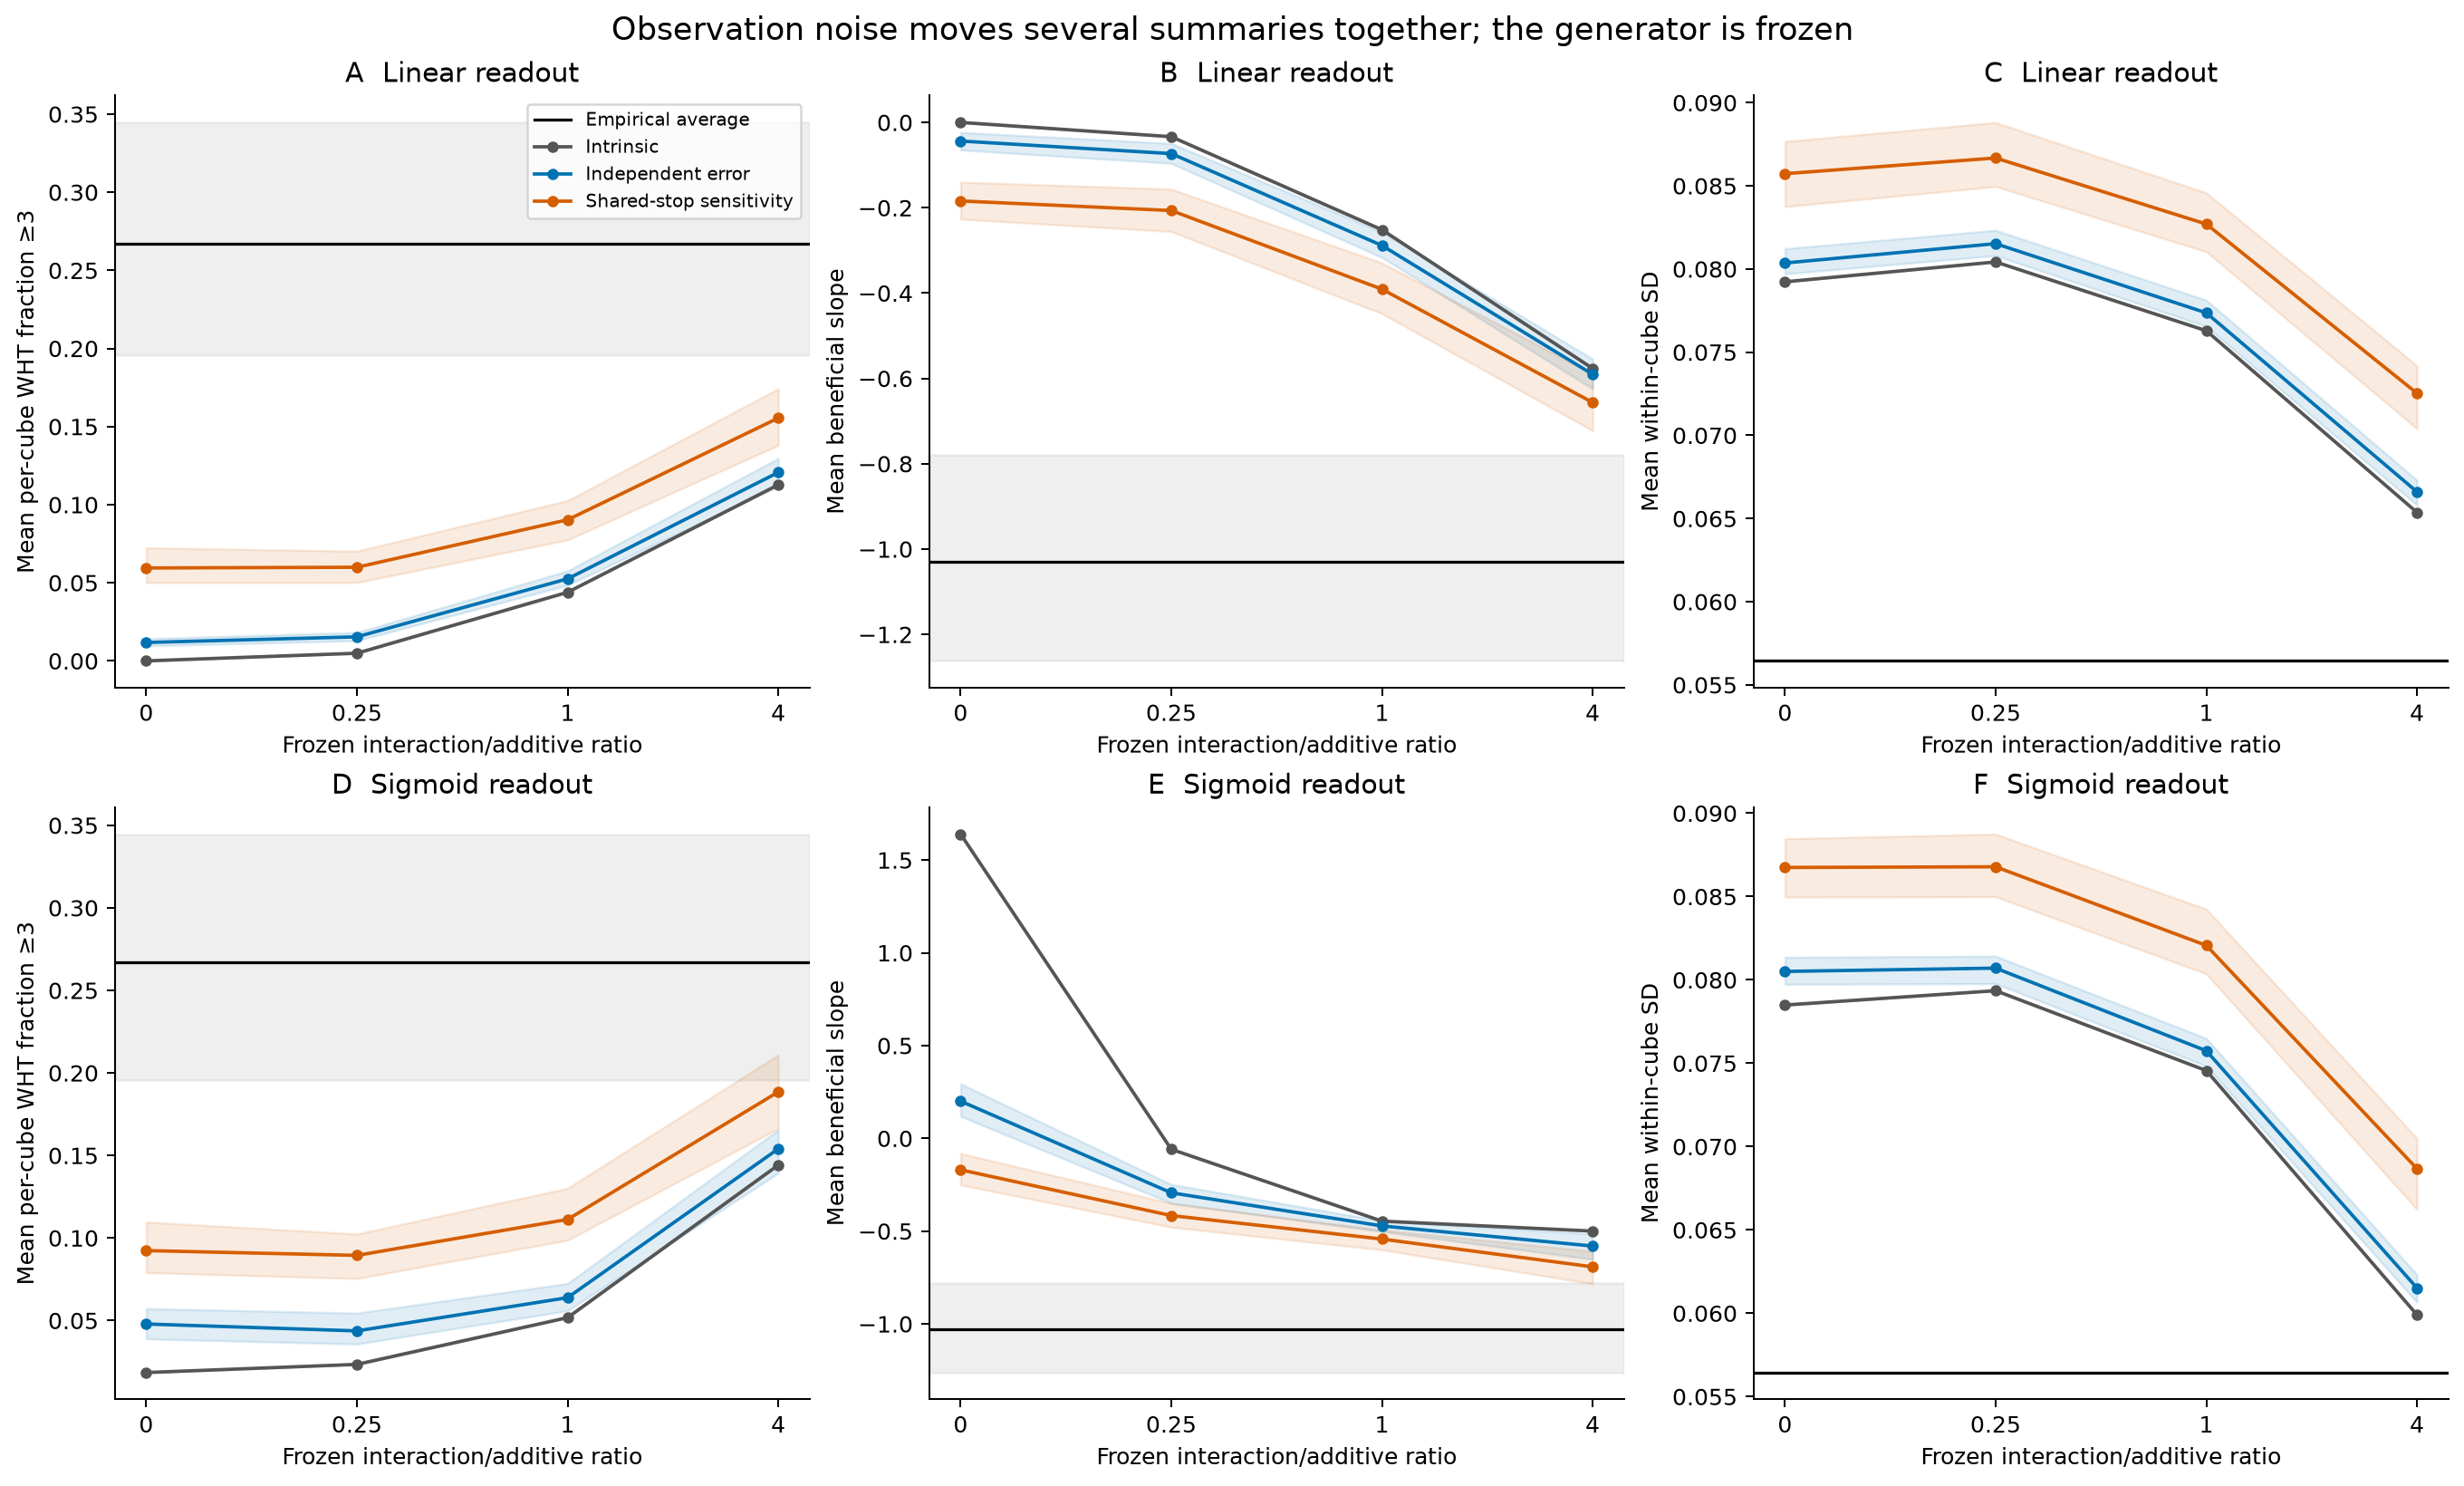

In [7]:
figure = tools.figure_models(context)
display(Image(filename=str(tools.FIGURES / '04_frozen_models_with_observation.png')))
plt.close(figure)

## 5. Activity strata expose different sampled populations

Half of the empirical confirmation cubes contain no active vertices. At r=4, the corresponding intrinsic counts are **11/64 linear** and **8/64 sigmoid**; under shared-stop observation they average **10.25/64** and **8.72/64**. Most synthetic cubes contain some active vertices. The models also contain all-active cubes, a stratum absent from the 24 empirical confirmation cubes. Empty empirical strata are kept empty; no favourable cubes are added.

Observation noise narrows some conditional differences, especially the sigmoid no-active high-order fraction, but the conditional comparisons do not repair the different activity composition. Moreover, activity is classified from noisy observations, so moving a vertex across a cutoff changes the population being summarized. Neither the full panel nor an activity-conditioned subset independently identifies the error-free landscape.

**Figure 5.** The r=4 frozen pair is shown in all three predeclared activity strata. Circles are linear, squares sigmoid; counts printed under each pair give mean synthetic cube membership out of 64 (linear left, sigmoid right). Black references and grey bootstrap bands use the available empirical stratum, with no reference drawn where it is empty. Whiskers show observation variation, not independent-landscape uncertainty. The complete resolution and estimator comparisons remain in the tables.

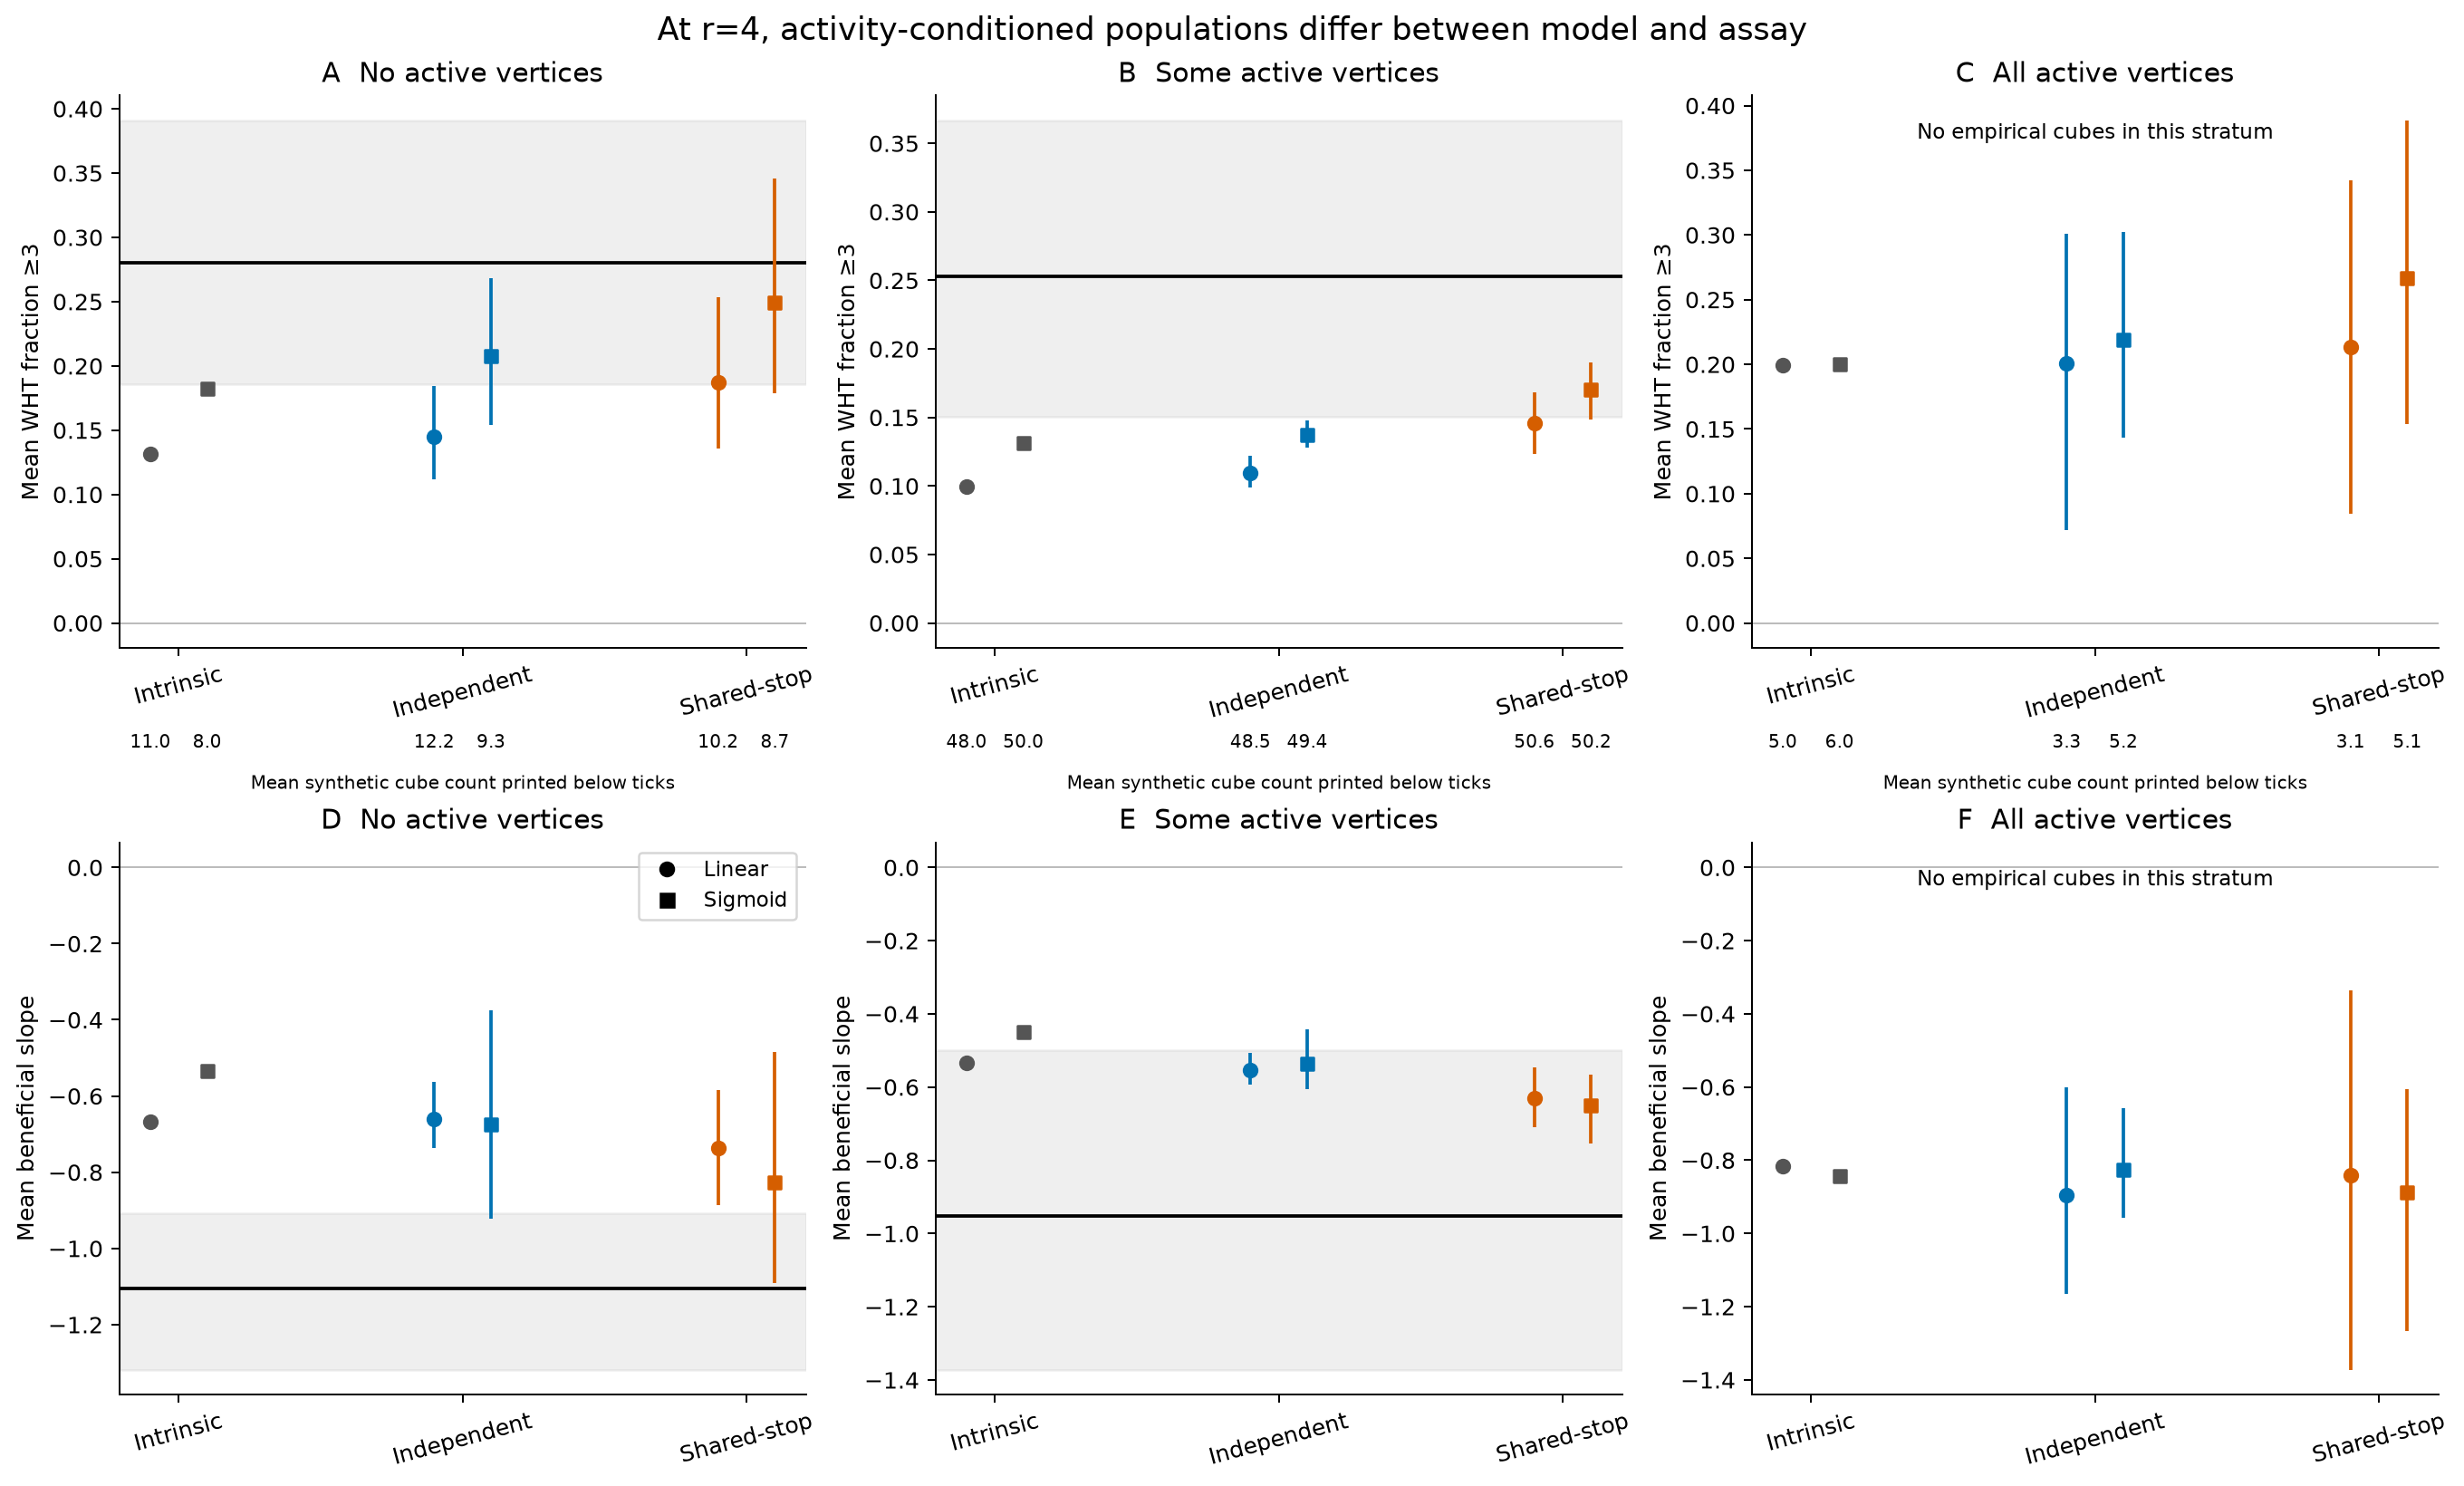

In [8]:
figure = tools.figure_strata(context)
display(Image(filename=str(tools.FIGURES / '05_activity_strata.png')))
plt.close(figure)

## Interpretation and limits

This RUN constrains the interpretation of ANA-064 without replacing its numerical findings. Independent replicate noise is insufficient to explain the mean per-cube WHT discrepancy under the cross-estimator assumptions. Shared assay variation can matter, but transferring stop covariance produces negative power estimates and unstable ratios near the floor. The analysis therefore does not yield a uniquely noise-corrected biological epistasis fraction or diminishing-returns rate.

The frozen generator captures some aggregate tendencies, and an explicit observation process explains part of the remaining difference. It does not jointly reproduce all reported summaries or activity composition. The discrepancy is also more heterogeneous than a single high-order fraction suggests: pooling powers and averaging cube fractions describe different aspects of the data. This is evidence about aggregate statistics of one complete four-site assay panel, not specific empirical interactions, a whole-protein spectrum, molecular free-energy parameters or arbitrary-length statistical transfer.

The inference remains consistent with the caution from [Reddy & Desai (2021), *Global epistasis emerges from a generic model of a complex trait*](https://doi.org/10.7554/eLife.64740): diminishing returns alone does not uniquely identify a saturating physical readout. [Sailer & Harms (2017), *Detecting High-Order Epistasis in Nonlinear Genotype-Phenotype Maps*](https://doi.org/10.1534/genetics.116.195214) motivates keeping phenotype scale and spectral interpretation explicit. These papers contextualize the estimators; the numerical findings here come from RUN-168.

## Reproducibility and audit

Slurm job **2313** completed with exit code **0**, empty stderr and a production runtime of **103.16 seconds**. All **162 remote file hashes**, **73 manifest output hashes**, **eight submission source hashes**, and **14 source/prepared input hashes** verify. The exact submitted source and completion logs are preserved alongside the outputs. Original full-archive MD5s were not checked because input retrieval used selected ZIP-member byte ranges; each retained member has verified CRC and SHA-256.

The independent notebook uses a butterfly Walsh transform and separately derived covariance calculations. It verifies all **768 empirical measurements**, **193,170 activity flags**, **1,664 genotype exclusions**, training/holdout assignments, every noise-estimation cell, **131,584 synthetic replicate-pair cubes** (including intrinsic references), **394,752 synthetic statistic rows**, **144 empirical statistic rows**, and **1,728 empirical mutation rows**. It replays **4,210,688 saved replicate values** from frozen landscapes and the recorded donor pools/random seed, independently checks 1,440 synthetic summary rows covering intrinsic and first/last observation draws, and reproduces all 108 original empirical-bootstrap rows.

Component checks use relative tolerance 10⁻¹⁰ and absolute tolerance 2×10⁻¹². CSV statistic checks use relative tolerance 2×10⁻⁷ and absolute tolerance 2×10⁻¹⁰; the maximum absolute difference is approximately 3.08×10⁻⁶ in an unstable ratio, within its relative tolerance. No numerical audit asserts scientific adequacy. Full per-cube arrays, signed powers, mutation components, eligibility masks and observation-draw identifiers remain available in the RUN bundle.

The canonical notebook executes the audits, tables and five figures; [README.md](../README.md) documents restoration and reproduction. Figures are exported as PNG and vector PDF. RUN outputs are DVC-tracked and backed up; `tables/data_bundle_audit.json` records backup verification. Repository-wide labproj checks timed out on historical cloud-backed records, so no global strict-check pass is claimed. No RES, CLAIM or additional experiment accompanies this ANA.
